# 07 · Gradient boosting y ensambles

**Proyecto:** predicción de complicaciones en pacientes hipertensos del SIS (Perú) · PUCP 1INF62 IA Aplicada 2026-2

Los cuadernos 02 a 05 dejaron un techo de ROC-AUC de **~0.70**. El Random Forest (0.705) y la GRU (0.703) empatan, pero aprenden cosas distintas: el bosque usa combinaciones de variables y la GRU, la dinámica de los últimos meses. Este cuaderno responde dos preguntas:

1. **¿Un modelo más fuerte para datos tabulares supera al Random Forest?** El *gradient boosting* es el estándar en datos tabulares clínicos: cada árbol corrige los errores de los anteriores, en vez de promediar árboles independientes como el bosque.
2. **¿Combinar modelos que aprenden cosas distintas rompe el techo?** Se prueban promedios simples y un *stacking* (una regresión logística que aprende a combinar las probabilidades).

**Hipótesis previas** (se escriben antes de ver los resultados para no ajustarlas después):
- El boosting mejora al Random Forest en +0.005 a +0.01 de ROC-AUC.
- El ensamble RF + GRU mejora más que el boosting solo, porque combina señales distintas (tabular y temporal).
- Ningún modelo pasa de ~0.72: el límite lo ponen las variables, no el algoritmo.

**Reglas para que la comparación sea justa:**
- Misma partición 80/20 de `03_random_forest.ipynb` (`random_state=42`, estratificada). Se comprueba paciente por paciente contra `predicciones_test_rf_rl.csv`.
- Los hiperparámetros se eligen **solo con train** (una validación interna), nunca mirando test.
- Las probabilidades del RF y de la GRU se leen de los archivos que guardaron 03 y 05: no se reentrenan.
- La GRU solo tiene predicciones de test, así que el *stacking* se ajusta con **validación cruzada dentro de test** (*cross-fitting*): cada paciente recibe una probabilidad de un combinador que no lo vio.
- Todos los modelos van **sin pesos de clase**, para que las probabilidades queden calibradas (ver 03 y 06).

## 1. Inicializar

In [1]:
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterSampler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from scipy.stats import spearmanr

try:
    import lightgbm as lgb
    HAY_LIGHTGBM = True
except ImportError:
    HAY_LIGHTGBM = False

SEED = 42

AZUL, NARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
MORADO, GRIS, TEXTO, TEXTO_2 = '#7e5bd6', '#a3a29b', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ad',
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlecolor': TEXTO, 'axes.labelcolor': TEXTO_2,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False,
})

def cronometro(t0):
    return f"{(time.time() - t0) / 60:.1f} min"

print("LightGBM instalado:", HAY_LIGHTGBM, "(opcional: si no está, se usa solo el boosting de scikit-learn)")

LightGBM instalado: False (opcional: si no está, se usa solo el boosting de scikit-learn)


In [2]:
# --- Parámetros del trabajo ---
RUTA_MANUAL = None          # ruta completa de dataset_consolidado.csv, si no está en data/processed/

# Búsqueda de hiperparámetros. El boosting es rápido: con estos valores, el cuaderno completo tarda
# unos 10-15 min en un portátil. Para una prueba rápida: N_AJUSTE = 30_000, N_ITER = 5
N_AJUSTE = 150_000          # pacientes de train usados en la búsqueda (el modelo final usa todo train)
N_ITER = 40                 # combinaciones que prueba la búsqueda aleatoria
N_PERMUTACION = 20_000      # pacientes de test para la importancia por permutación
N_BOOT = 500                # remuestreos bootstrap

def buscar_dataset(nombre='dataset_consolidado.csv'):
    if RUTA_MANUAL:
        return Path(RUTA_MANUAL)
    for p in [Path.cwd(), *Path.cwd().parents]:
        for d in (p, p / 'data' / 'processed'):
            if (d / nombre).exists():
                return d / nombre
    raise FileNotFoundError(f"No se encontró {nombre}. Ejecuta primero src/preprocessing.ipynb o usa RUTA_MANUAL.")

def buscar_archivo(nombre):
    # Las predicciones de 03 y 05 se guardan junto al dataset; si no, se buscan en todo el proyecto
    if (RUTA_PROC / nombre).exists():
        return RUTA_PROC / nombre
    for base in [RAIZ, Path.cwd(), Path.cwd().parent]:
        encontrados = sorted(base.rglob(nombre))
        if encontrados:
            return encontrados[0]
    return None

RUTA_DATASET = buscar_dataset()
RUTA_PROC = RUTA_DATASET.parent
RAIZ = RUTA_PROC.parents[1] if RUTA_PROC.name == 'processed' and RUTA_PROC.parent.name == 'data' else RUTA_PROC
RUTA_RESULTADOS = RAIZ / 'results' if (RAIZ / 'data').is_dir() else RUTA_PROC
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARCH_RF = buscar_archivo('predicciones_test_rf_rl.csv')
ARCH_GRU = buscar_archivo('predicciones_test_gru.csv')
ARCH_HIPER_RF = buscar_archivo('mejores_hiperparametros_rf.csv')
assert ARCH_RF is not None, "Falta predicciones_test_rf_rl.csv: ejecuta 03_random_forest.ipynb (versión actual)."
print("Dataset:", RUTA_DATASET)
print("Predicciones RF/RL:", ARCH_RF)
print("Predicciones GRU:", ARCH_GRU if ARCH_GRU else "no encontradas (se omiten los ensambles con la GRU)")
print("Resultados en:", RUTA_RESULTADOS)

Dataset: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\data\processed\dataset_consolidado.csv
Predicciones RF/RL: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\data\processed\predicciones_test_rf_rl.csv
Predicciones GRU: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\data\processed\predicciones_test_gru.csv
Resultados en: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\results


## 2. Datos y partición

Se reconstruye la partición de `03_random_forest.ipynb` y se comprueba que los pacientes de test y su `y` sean exactamente los del archivo de predicciones. Si no coinciden, cualquier comparación con el RF o la GRU sería engañosa, así que el cuaderno se detiene.

In [3]:
df = pd.read_csv(RUTA_DATASET, index_col='paciente')
COLS_ELIMINAR = [c for c in ['dias_hosp', 'pad_media'] if c in df.columns]
y = df['y']
X = df.drop(columns=['y'] + COLS_ELIMINAR)
VARIABLES = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

# Validación interna (dentro de train) para elegir hiperparámetros, igual que en 03
idx_tr, idx_val = train_test_split(X_train.index, test_size=0.2, random_state=SEED, stratify=y_train)
n_aj = min(N_AJUSTE, len(idx_tr))
idx_aj = idx_tr if n_aj == len(idx_tr) else train_test_split(
    idx_tr, train_size=n_aj, random_state=SEED, stratify=y_train.loc[idx_tr])[0]

# Control paciente por paciente contra 03_random_forest.ipynb
pred_rf = pd.read_csv(ARCH_RF)
pred_rf['paciente'] = pred_rf['paciente'].astype(X_test.index.dtype)
pred_rf = pred_rf.set_index('paciente')
assert set(pred_rf.index) == set(X_test.index), \
    "Los pacientes de test no coinciden con predicciones_test_rf_rl.csv: vuelve a ejecutar 03_random_forest.ipynb"
pred_rf = pred_rf.loc[X_test.index]
assert (pred_rf['y'].to_numpy() == y_test.to_numpy()).all(), "El y de test no coincide con 03_random_forest.ipynb"
print("Partición idéntica a 03_random_forest.ipynb ✔")

prob_test = {'Random Forest': pred_rf['prob_rf'].to_numpy(),
             'Regresión logística': pred_rf['prob_rl_sin_pesos'].to_numpy()}

if ARCH_GRU is not None:
    pred_gru = pd.read_csv(ARCH_GRU)
    pred_gru['paciente'] = pred_gru['paciente'].astype(X_test.index.dtype)
    pred_gru = pred_gru.set_index('paciente')
    col_gru = next(c for c in pred_gru.columns if c.lower() == 'prob_gru')
    assert set(pred_gru.index) == set(X_test.index), "Los pacientes de test de la GRU no coinciden"
    pred_gru = pred_gru.loc[X_test.index]
    assert (pred_gru['y'].to_numpy() == y_test.to_numpy()).all(), "El y de test de la GRU no coincide"
    prob_test['GRU'] = pred_gru[col_gru].to_numpy()
    print("Predicciones de la GRU alineadas ✔")

pd.DataFrame({
    'Conjunto': ['Train (completo)', '  ↳ submuestra para la búsqueda', '  ↳ validación interna', 'Test'],
    'Pacientes': [len(X_train), len(idx_aj), len(idx_val), len(X_test)],
    '% y=1': [y_train.mean() * 100, y_train.loc[idx_aj].mean() * 100, y_train.loc[idx_val].mean() * 100,
              y_test.mean() * 100],
}).round(2).assign(Variables=X.shape[1])

Partición idéntica a 03_random_forest.ipynb ✔
Predicciones de la GRU alineadas ✔


,Conjunto,Pacientes,% y=1,Variables
0,Train (completo),335380,5.6,34
1,↳ submuestra para la búsqueda,150000,5.6,34
2,↳ validación interna,67076,5.6,34
3,Test,83846,5.6,34


In [4]:
def metricas(y_true, prob):
    y_true = np.asarray(y_true)
    top = np.argsort(-prob)[:int(len(prob) * 0.10)]
    return {'ROC-AUC': roc_auc_score(y_true, prob), 'PR-AUC': average_precision_score(y_true, prob),
            'Brier': brier_score_loss(y_true, prob), 'Captura top 10% (%)': y_true[top].sum() / y_true.sum() * 100}

def bootstrap_vs(y_true, probs, referencia, n=N_BOOT, seed=SEED):
    # Bootstrap PAREADO: los mismos pacientes remuestreados para todos los modelos
    y_true = np.asarray(y_true)
    rng = np.random.default_rng(seed)
    filas = []
    for _ in range(n):
        b = rng.integers(0, len(y_true), len(y_true))
        ref = roc_auc_score(y_true[b], probs[referencia][b])
        filas.append({k: roc_auc_score(y_true[b], p[b]) - ref for k, p in probs.items() if k != referencia})
    d = pd.DataFrame(filas)
    return pd.DataFrame({'Δ ROC-AUC': d.mean(), 'IC 95% inf': d.quantile(0.025), 'IC 95% sup': d.quantile(0.975),
                         '¿Significativa?': np.where((d.quantile(0.025) > 0) | (d.quantile(0.975) < 0), 'Sí', 'No')})

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

y_tr_np, y_te_np = y_train.to_numpy(), y_test.to_numpy()
pd.DataFrame({k: metricas(y_te_np, p) for k, p in prob_test.items()}).T.round(4) \
  .rename_axis('Modelos ya entrenados (control: deben coincidir con 03 y 05)')

,ROC-AUC,PR-AUC,Brier,Captura top 10% (%)
Modelos ya entrenados (control: deben coincidir con 03 y 05),,,,
Random Forest,0.7050,0.1241,0.0512,26.3247
Regresión logística,0.6918,0.1177,0.0515,24.7712
GRU,0.7028,0.1252,0.0512,26.6014


**Control.** La partición coincide paciente por paciente con `03_random_forest.ipynb` y con la GRU, y las métricas de los modelos ya entrenados son exactamente las reportadas en 03 y 05 (Random Forest 0.7050, GRU 0.7028, regresión logística 0.6918). Toda la comparación que sigue usa los mismos 83,846 pacientes de test.

## 3. Gradient boosting (scikit-learn)

Se usa `HistGradientBoostingClassifier`, la implementación de scikit-learn inspirada en LightGBM:
- **Agrupa cada variable en 255 intervalos** (histogramas), lo que lo hace rápido con cientos de miles de pacientes.
- **Maneja los faltantes de forma nativa**: aprende en cada división hacia qué lado mandar a los pacientes sin medición de presión, en vez de imputarles la mediana. Puede ser una ventaja, porque "no tener presión medida" es informativo.
- **Parada temprana**: deja de agregar árboles cuando la pérdida en una validación interna no mejora en 30 iteraciones.

| Hiperparámetro | Qué controla | Valores probados |
|---|---|---|
| `learning_rate` | Cuánto corrige cada árbol. Más bajo = más árboles, pero suele generalizar mejor | 0.02 a 0.15 |
| `max_leaf_nodes` | Complejidad de cada árbol (interacciones que puede captar) | 15 a 127 |
| `min_samples_leaf` | Pacientes mínimos por hoja: el regularizador clave, igual que en el RF | 20 a 2000 |
| `l2_regularization` | Penaliza hojas con valores extremos | 0 a 10 |
| `max_features` | Fracción de variables por división (añade aleatoriedad, como en el RF) | 0.5 a 1.0 |

La búsqueda entrena en una submuestra de train y evalúa el ROC-AUC en la validación interna. El ganador se reentrena con **todo train** y se evalúa una sola vez en test.

In [5]:
import inspect
ACEPTA_MAX_FEATURES = 'max_features' in inspect.signature(HistGradientBoostingClassifier).parameters  # scikit-learn ≥ 1.4

espacio = {
    'learning_rate': [0.02, 0.03, 0.05, 0.08, 0.1, 0.15],
    'max_leaf_nodes': [15, 31, 63, 127],
    'min_samples_leaf': [20, 100, 300, 1000, 2000],
    'l2_regularization': [0.0, 0.1, 1.0, 10.0],
}
if ACEPTA_MAX_FEATURES:
    espacio['max_features'] = [0.5, 0.7, 1.0]

def nuevo_hgb(**params):
    return HistGradientBoostingClassifier(max_iter=2000, early_stopping=True, validation_fraction=0.1,
                                          n_iter_no_change=30, random_state=SEED, **params)

t0 = time.time()
filas = []
for i, params in enumerate(ParameterSampler(espacio, n_iter=N_ITER, random_state=SEED)):
    m = nuevo_hgb(**params).fit(X_train.loc[idx_aj], y_train.loc[idx_aj])
    auc = roc_auc_score(y_train.loc[idx_val], m.predict_proba(X_train.loc[idx_val])[:, 1])
    filas.append({**params, 'Árboles (parada temprana)': m.n_iter_, 'ROC-AUC validación': auc})
busqueda_hgb = pd.DataFrame(filas).sort_values('ROC-AUC validación', ascending=False).reset_index(drop=True)
print(f"Búsqueda: {N_ITER} combinaciones en {cronometro(t0)}")
busqueda_hgb.head(10).round(4)

Búsqueda: 40 combinaciones en 2.4 min


,min_samples_leaf,max_leaf_nodes,max_features,learning_rate,l2_regularization,Árboles (parada temprana),ROC-AUC validación
0,100,15,0.7,0.05,0.0,331,0.7108
1,300,31,0.5,0.05,1.0,150,0.7101
2,20,15,0.5,0.03,10.0,454,0.7100
3,100,31,0.7,0.02,1.0,413,0.7100
4,2000,31,0.7,0.02,0.0,438,0.7092
5,300,63,1.0,0.03,10.0,205,0.7088
6,20,15,1.0,0.08,1.0,155,0.7088
7,2000,15,0.5,0.10,1.0,147,0.7088
8,300,15,1.0,0.15,10.0,111,0.7087
9,1000,15,0.7,0.05,10.0,219,0.7087


**Resultado de la búsqueda.** Las 40 combinaciones quedaron entre 0.694 y 0.711 de ROC-AUC en la validación interna, y las diez mejores dentro de 0.002 (0.7087-0.7108). El boosting es **poco sensible a sus hiperparámetros** en este problema: casi cualquier configuración razonable da el mismo resultado.

El gráfico muestra dos patrones claros:
- **Ganan los árboles pequeños** (15 a 31 hojas). Con 63 o 127 hojas el AUC baja. La señal está en interacciones de **pocas variables**, no en combinaciones complejas.
- **Las tasas de aprendizaje bajas (0.02-0.05) superan a las altas** (0.08-0.15), como es habitual: muchos pasos pequeños generalizan mejor que pocos grandes.

La regularización (`min_samples_leaf`, `l2_regularization`) apenas influye, porque con 150 mil pacientes y árboles pequeños hay poco riesgo de sobreajuste.

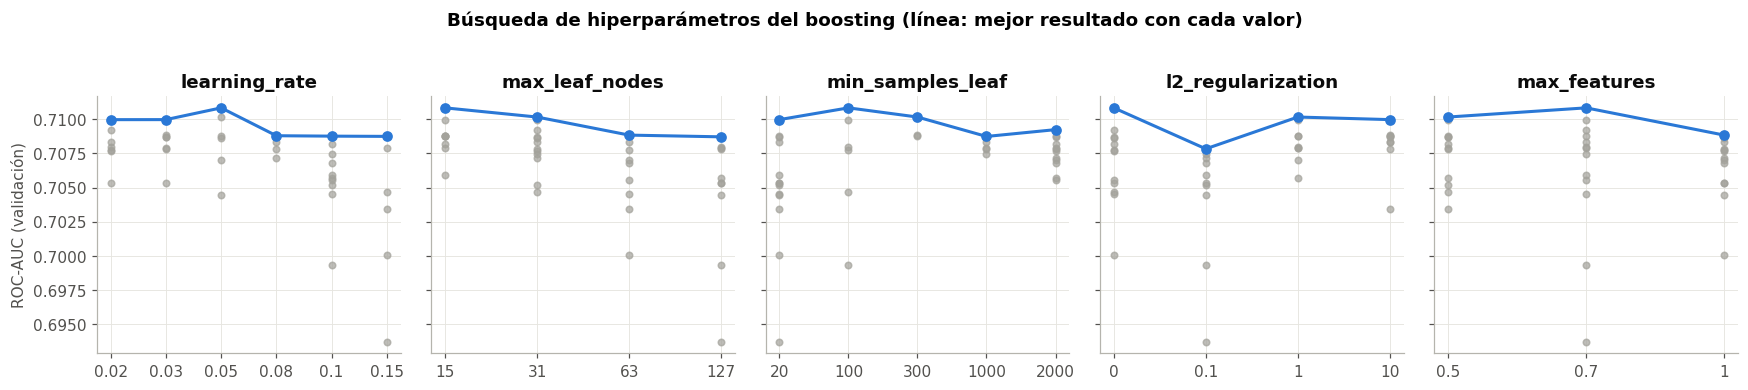

In [6]:
fig, axes = plt.subplots(1, len(espacio), figsize=(3.2 * len(espacio), 3.4), sharey=True)
for ax, p in zip(axes, espacio):
    valores = sorted(espacio[p])                       # eje X en orden numérico, con todos los valores probables
    pos = {v: i for i, v in enumerate(valores)}
    x = busqueda_hgb[p].map(lambda v: pos[min(valores, key=lambda w: abs(w - v))])
    ax.scatter(x, busqueda_hgb['ROC-AUC validación'], color=GRIS, s=18, alpha=0.7)
    mejor = busqueda_hgb.groupby(x)['ROC-AUC validación'].max()
    ax.plot(mejor.index, mejor.values, color=AZUL, marker='o', linewidth=2)
    ax.set_xticks(range(len(valores)), [f'{v:g}' for v in valores])
    ax.set(title=p, xlabel='')
axes[0].set_ylabel('ROC-AUC (validación)')
fig.suptitle('Búsqueda de hiperparámetros del boosting (línea: mejor resultado con cada valor)', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

In [7]:
t0 = time.time()
mejores_hgb = {k: busqueda_hgb.loc[0, k] for k in espacio}
mejores_hgb = {k: (int(v) if k in ('max_leaf_nodes', 'min_samples_leaf') else float(v)) for k, v in mejores_hgb.items()}
hgb = nuevo_hgb(**mejores_hgb).fit(X_train, y_train)
prob_test['Gradient boosting'] = hgb.predict_proba(X_test)[:, 1]
print("Hiperparámetros elegidos:", mejores_hgb)
print(f"Árboles tras la parada temprana: {hgb.n_iter_} | entrenamiento con todo train: {cronometro(t0)}")
pd.DataFrame({k: metricas(y_te_np, prob_test[k]) for k in ['Gradient boosting', 'Random Forest']}).T.round(4)

Hiperparámetros elegidos: {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 100, 'l2_regularization': 0.0, 'max_features': 0.7}
Árboles tras la parada temprana: 378 | entrenamiento con todo train: 0.1 min


,ROC-AUC,PR-AUC,Brier,Captura top 10% (%)
Gradient boosting,0.709,0.1328,0.0510,27.0696
Random Forest,0.705,0.1241,0.0512,26.3247


**Resultado en test.** El boosting elegido (tasa 0.05, 15 hojas, al menos 100 pacientes por hoja, 70% de las variables por división) usa 378 árboles y se entrena en **seis segundos** con todo train, frente a varios minutos del Random Forest de 500 árboles.

| | Gradient boosting | Random Forest | Diferencia |
|---|---|---|---|
| ROC-AUC | **0.7090** | 0.7050 | +0.004 |
| PR-AUC | **0.1328** | 0.1241 | **+7%** |
| Brier | 0.0510 | 0.0512 | igual |
| Captura top 10% | **27.1%** | 26.3% | +0.8 puntos |

La mejora en ROC-AUC es pequeña, pero en **PR-AUC es del 7%**: el boosting es mejor justo donde importa, ordenando a los pacientes de mayor riesgo. El ROC-AUC en test (0.709) es casi igual al de la validación interna (0.711), así que la búsqueda no sobreajustó.

### 3.1 Curva de aprendizaje del boosting

La pérdida en la validación interna del propio boosting en función del número de árboles. Si baja y se estabiliza, la parada temprana eligió bien; si sube al final, el modelo empezaba a sobreajustar.

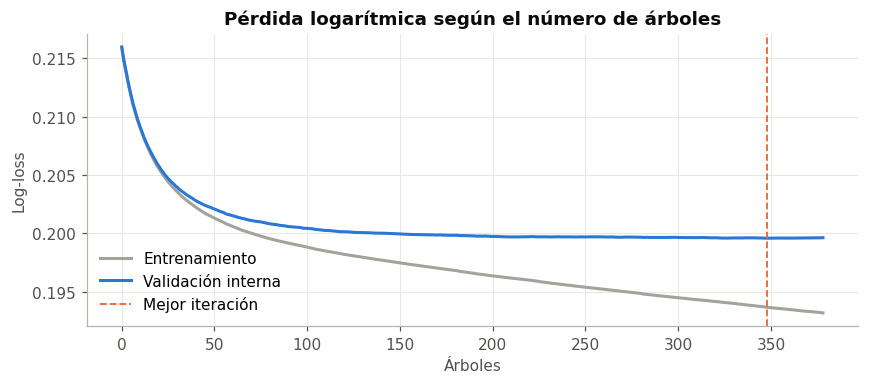

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
# train_score_ y validation_score_ empiezan en la iteración 0 (antes del primer árbol); el puntaje es −log-loss
ax.plot(np.arange(len(hgb.train_score_)), -hgb.train_score_, color=GRIS, linewidth=2, label='Entrenamiento')
ax.plot(np.arange(len(hgb.validation_score_)), -hgb.validation_score_, color=AZUL, linewidth=2,
        label='Validación interna')
ax.axvline(int(np.argmax(hgb.validation_score_)), color=NARANJA, linestyle='--', linewidth=1.2, label='Mejor iteración')
ax.set(title='Pérdida logarítmica según el número de árboles', xlabel='Árboles', ylabel='Log-loss')
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.** La pérdida de validación baja rápido en los primeros ~100 árboles y se aplana hacia los 200. Desde ahí, la pérdida de entrenamiento sigue bajando pero la de validación no: el modelo empezaría a memorizar train sin mejorar en pacientes nuevos. La parada temprana se detuvo en la iteración ~350, cuando la validación llevaba 30 árboles sin mejorar. **No hay sobreajuste visible**: la curva de validación nunca sube.

## 4. LightGBM (opcional)

Solo se ejecuta si `lightgbm` está instalado (`pip install lightgbm`). Es la implementación de referencia del *gradient boosting* por histogramas; la de scikit-learn es muy parecida, así que se espera un resultado casi igual. Sirve para demostrar en el informe que el resultado no depende de la librería.

In [9]:
if HAY_LIGHTGBM:
    t0 = time.time()
    espacio_lgb = {
        'learning_rate': [0.02, 0.03, 0.05, 0.08, 0.1],
        'num_leaves': [15, 31, 63, 127],
        'min_child_samples': [20, 100, 300, 1000, 2000],
        'reg_lambda': [0.0, 0.1, 1.0, 10.0],
        'colsample_bytree': [0.5, 0.7, 1.0],
        'subsample': [0.7, 1.0],
    }
    filas = []
    for params in ParameterSampler(espacio_lgb, n_iter=N_ITER, random_state=SEED):
        m = lgb.LGBMClassifier(n_estimators=3000, subsample_freq=1, random_state=SEED, verbose=-1, **params)
        m.fit(X_train.loc[idx_aj], y_train.loc[idx_aj], eval_set=[(X_train.loc[idx_val], y_train.loc[idx_val])],
              eval_metric='auc', callbacks=[lgb.early_stopping(50, verbose=False)])
        auc = roc_auc_score(y_train.loc[idx_val], m.predict_proba(X_train.loc[idx_val])[:, 1])
        filas.append({**params, 'Árboles': m.best_iteration_, 'ROC-AUC validación': auc})
    busqueda_lgb = pd.DataFrame(filas).sort_values('ROC-AUC validación', ascending=False).reset_index(drop=True)
    mejores_lgb = {k: busqueda_lgb.loc[0, k] for k in espacio_lgb}
    mejores_lgb = {k: (int(v) if k in ('num_leaves', 'min_child_samples') else float(v)) for k, v in mejores_lgb.items()}
    n_arboles_lgb = int(busqueda_lgb.loc[0, 'Árboles'] * len(X_train) / len(idx_aj))  # más datos → algo más de árboles
    modelo_lgb = lgb.LGBMClassifier(n_estimators=max(n_arboles_lgb, 50), subsample_freq=1, random_state=SEED,
                                    verbose=-1, **mejores_lgb).fit(X_train, y_train)
    prob_test['LightGBM'] = modelo_lgb.predict_proba(X_test)[:, 1]
    print("Hiperparámetros elegidos:", mejores_lgb, "| árboles:", max(n_arboles_lgb, 50), "|", cronometro(t0))
    display(busqueda_lgb.head(5).round(4))
else:
    print("LightGBM no está instalado: se omite esta sección (el boosting de scikit-learn ya cubre la comparación).")

LightGBM no está instalado: se omite esta sección (el boosting de scikit-learn ya cubre la comparación).


## 5. ¿Qué aprende el boosting? Importancia por permutación

Misma técnica que en 03: cuánto cae el ROC-AUC de test si se desordena una variable. Si el boosting coincide con el RF en las variables principales, ambos encontraron la misma señal y la diferencia entre ellos está en **cómo** la combinan.

Tiempo: 0.3 min


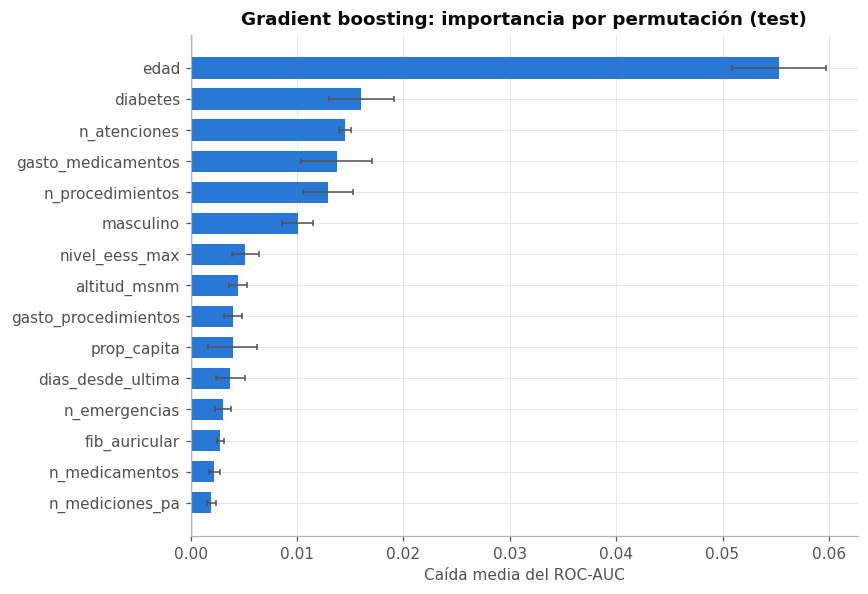

,Caída del ROC-AUC
edad,0.0553
diabetes,0.0161
n_atenciones,0.0145
gasto_medicamentos,0.0137
n_procedimientos,0.0129
masculino,0.0100
nivel_eess_max,0.0051
altitud_msnm,0.0045
gasto_procedimientos,0.0040
prop_capita,0.0039


In [10]:
t0 = time.time()
n_perm = min(N_PERMUTACION, len(X_test))
idx_perm = X_test.index if n_perm == len(X_test) else train_test_split(
    X_test.index, train_size=n_perm, random_state=SEED, stratify=y_test)[0]
perm = permutation_importance(hgb, X_test.loc[idx_perm], y_test.loc[idx_perm], scoring='roc_auc',
                              n_repeats=5, random_state=SEED, n_jobs=1)
imp_hgb = pd.Series(perm.importances_mean, index=VARIABLES).sort_values()
err_hgb = pd.Series(perm.importances_std, index=VARIABLES)[imp_hgb.index]
print("Tiempo:", cronometro(t0))

top = imp_hgb.tail(15)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, xerr=err_hgb[top.index], color=AZUL, height=0.7,
        error_kw={'ecolor': TEXTO_2, 'elinewidth': 1, 'capsize': 2})
ax.axvline(0, color=TEXTO_2, linewidth=0.8)
ax.set(title='Gradient boosting: importancia por permutación (test)', xlabel='Caída media del ROC-AUC')
plt.tight_layout()
plt.show()
imp_hgb.sort_values(ascending=False).head(10).round(4).to_frame('Caída del ROC-AUC')

**Lectura.** El boosting encontró **la misma señal que el Random Forest**. La edad domina con amplia ventaja (0.055 de caída del AUC, igual que en el bosque: 0.054), seguida por diabetes, uso del sistema (`n_atenciones`, `n_procedimientos`), gasto en medicamentos y sexo masculino. Comparado con el bosque, el boosting da algo más de peso a `n_atenciones`, una variable cuya relación con el riesgo no es lineal (en 06 se vio que más atenciones protegen frente a los eventos graves).

Que los dos modelos coincidan en las variables principales indica que **la diferencia entre ellos está en cómo combinan la información**, no en qué información usan.

## 6. Ensambles

Un ensamble solo mejora si sus modelos **se equivocan en pacientes distintos**. Por eso, antes de combinar, se mide cuánto se parecen sus predicciones: la correlación de Spearman entre los rankings de riesgo. Si dos modelos ordenan casi igual a los pacientes (correlación ~0.99), promediarlos no aporta nada.

Se prueban dos formas de combinar:
- **Promedio simple** de probabilidades. No se ajusta nada, así que no hay riesgo de sobreajuste y la probabilidad sigue calibrada si los modelos lo están.
- **Stacking**: una regresión logística que recibe el *logit* de cada modelo y aprende cuánto pesar a cada uno. Como la GRU solo tiene predicciones de test, se ajusta con **validación cruzada de 5 particiones dentro de test**: el combinador que predice a un paciente nunca lo vio.

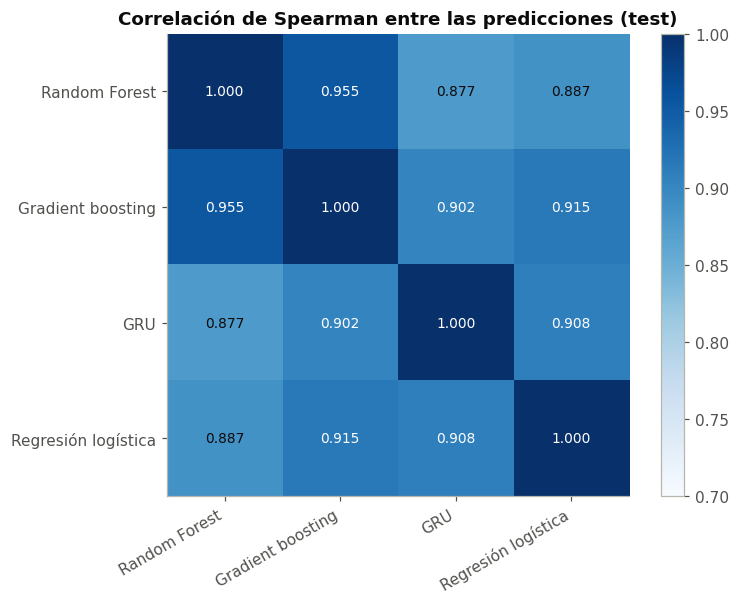

In [11]:
base = [m for m in ['Random Forest', 'Gradient boosting', 'LightGBM', 'GRU', 'Regresión logística'] if m in prob_test]
rank = pd.DataFrame({m: prob_test[m] for m in base})
corr = rank.corr(method='spearman')

fig, ax = plt.subplots(figsize=(1.3 * len(base) + 2, 1.1 * len(base) + 1.2))
im = ax.imshow(corr.values, cmap='Blues', vmin=0.7, vmax=1)
ax.set_xticks(range(len(base)), base, rotation=30, ha='right')
ax.set_yticks(range(len(base)), base)
for i in range(len(base)):
    for j in range(len(base)):
        ax.text(j, i, f'{corr.values[i, j]:.3f}', ha='center', va='center',
                color='white' if corr.values[i, j] > 0.9 else TEXTO, fontsize=9)
ax.grid(False)
ax.set_title('Correlación de Spearman entre las predicciones (test)')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

**Lectura.** El Random Forest y el boosting ordenan a los pacientes de forma muy parecida (**0.955**), así que promediarlos aporta poco. La GRU es el modelo **más distinto** de los tabulares: 0.877 con el Random Forest y 0.902 con el boosting. Es lo esperable, porque la GRU ve la historia mes a mes y los tabulares, resúmenes de dos años. **Los ensambles que incluyen a la GRU son los que tienen más margen para mejorar.**

In [12]:
def promedio(*nombres):
    return np.mean([prob_test[n] for n in nombres], axis=0)

ensambles = {}
abrev = {'Random Forest': 'RF', 'Gradient boosting': 'GB', 'LightGBM': 'LGBM', 'GRU': 'GRU'}
candidatos = [('Random Forest', 'Gradient boosting')]
if 'GRU' in prob_test:
    candidatos += [('Random Forest', 'GRU'), ('Gradient boosting', 'GRU'), ('Random Forest', 'Gradient boosting', 'GRU')]
if 'LightGBM' in prob_test:
    candidatos += [('Random Forest', 'Gradient boosting', 'LightGBM')] + \
                  ([('Random Forest', 'Gradient boosting', 'LightGBM', 'GRU')] if 'GRU' in prob_test else [])
for c in candidatos:
    ensambles['Promedio ' + ' + '.join(abrev[n] for n in c)] = promedio(*c)

# Stacking con cross-fitting dentro de test
def stacking(nombres, k=5):
    Z = np.column_stack([logit(prob_test[n]) for n in nombres])
    salida = np.zeros(len(y_te_np))
    pesos = []
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=SEED).split(Z, y_te_np):
        meta = LogisticRegression(C=1.0, max_iter=1000).fit(Z[tr], y_te_np[tr])
        salida[te] = meta.predict_proba(Z[te])[:, 1]
        pesos.append(meta.coef_[0])
    return salida, pd.Series(np.mean(pesos, axis=0), index=nombres)

comp_stack = [m for m in ['Random Forest', 'Gradient boosting', 'LightGBM', 'GRU'] if m in prob_test]
ensambles['Stacking ' + ' + '.join(abrev[n] for n in comp_stack)], pesos_stack = stacking(comp_stack)
prob_test.update(ensambles)

print("Pesos medios del stacking (sobre el logit de cada modelo):")
print(pesos_stack.round(3).to_string())

Pesos medios del stacking (sobre el logit de cada modelo):
Random Forest        0.148
Gradient boosting    0.578
GRU                  0.365


**Lectura de los pesos.** El stacking da el mayor peso al boosting (0.58), un peso considerable a la GRU (0.37) y poco al Random Forest (0.15). Una vez que el combinador tiene el boosting, el bosque es casi redundante (correlación 0.955); en cambio, la GRU conserva un peso alto porque aporta **información que los modelos tabulares no tienen**: la dinámica de los últimos meses.

## 7. Comparación final

Todas las métricas en el mismo test de 83 mil pacientes. Las diferencias de ROC-AUC frente al Random Forest se acompañan de un intervalo de confianza **bootstrap pareado** (los mismos pacientes remuestreados para todos los modelos): una diferencia solo cuenta si su intervalo no incluye el cero.

In [ ]:
tabla = pd.DataFrame({k: metricas(y_te_np, p) for k, p in prob_test.items()}).T.sort_values('ROC-AUC', ascending=False)
tabla['Tipo'] = ['Ensamble' if k in ensambles else 'Modelo' for k in tabla.index]
t0 = time.time()
delta_rf = bootstrap_vs(y_te_np, prob_test, 'Random Forest')
print("Bootstrap:", cronometro(t0))
tabla_final = tabla.join(delta_rf.rename(columns={'Δ ROC-AUC': 'Δ vs RF'}))
tabla_final.round(4)

**Resultado.** Los seis ensambles y el boosting superan al Random Forest de forma significativa. El mejor es el **promedio simple de RF + boosting + GRU (0.7121, +0.0071, IC 95%: 0.0053-0.0089)**. El stacking (0.7119) y el promedio boosting + GRU (0.7117, con el mejor PR-AUC: 0.1343) quedan prácticamente empatados con él.

Tres observaciones:
- **La diversidad importa más que la fuerza individual.** RF + GRU (0.7101) supera al boosting solo (0.7090), aunque cada uno por separado es peor que el boosting. Combinar dos modelos que se equivocan en pacientes distintos rinde más que mejorar uno.
- **RF + boosting apenas suma** (0.7096 frente a 0.7090 del boosting solo): son demasiado parecidos.
- **El stacking no supera al promedio simple.** Aprender los pesos no compensa: con modelos de calidad parecida, el promedio es igual de bueno, más simple y sin riesgo de sobreajuste.

Como los ensambles se compararon en el mismo test que se usó para elegir el mejor, la cifra del ganador puede ser ligeramente optimista. Pero los tres primeros están dentro de 0.0004 entre sí, así que la elección no cambia la conclusión.

In [ ]:
orden = tabla_final.sort_values('ROC-AUC')
fig, axes = plt.subplots(1, 2, figsize=(14, 0.45 * len(orden) + 1.5), gridspec_kw={'width_ratios': [1, 1]})
colores = [NARANJA if t == 'Ensamble' else AZUL for t in orden['Tipo']]
axes[0].barh(orden.index, orden['ROC-AUC'], color=colores, height=0.65)
for i, v in enumerate(orden['ROC-AUC']):
    axes[0].text(v + 0.0005, i, f'{v:.4f}', va='center', fontsize=9, color=TEXTO_2)
axes[0].set_xlim(orden['ROC-AUC'].min() - 0.01, orden['ROC-AUC'].max() + 0.008)
axes[0].set(title='ROC-AUC en test (azul: modelo · naranja: ensamble)', xlabel='ROC-AUC')

d = orden.drop(index='Random Forest')
axes[1].errorbar(d['Δ vs RF'], np.arange(len(d)),
                 xerr=[d['Δ vs RF'] - d['IC 95% inf'], d['IC 95% sup'] - d['Δ vs RF']],
                 fmt='o', color=TEXTO_2, ecolor=GRIS, elinewidth=2, capsize=3)
axes[1].scatter(d['Δ vs RF'], np.arange(len(d)), c=[NARANJA if t == 'Ensamble' else AZUL for t in d['Tipo']], zorder=3, s=40)
axes[1].axvline(0, color=TEXTO, linewidth=1)
axes[1].set_yticks(np.arange(len(d)), d.index)
axes[1].set(title='Diferencia de ROC-AUC frente al Random Forest (IC 95%)', xlabel='Δ ROC-AUC')
plt.tight_layout()
plt.show()

### 7.1 Calibración y utilidad clínica

Un ensamble puede ordenar mejor pero dar probabilidades peores. Se compara la calibración del RF, el mejor modelo individual y el mejor ensamble, y su beneficio neto en la curva de decisión (misma definición que en 06).

In [ ]:
mejor_modelo = tabla_final[tabla_final['Tipo'] == 'Modelo'].index[0]
mejor_ensamble = tabla_final[tabla_final['Tipo'] == 'Ensamble'].index[0]
elegidos = list(dict.fromkeys(['Random Forest', mejor_modelo, mejor_ensamble]))
col = {'Random Forest': AZUL, mejor_modelo: AQUA if mejor_modelo != 'Random Forest' else AZUL, mejor_ensamble: NARANJA}

def beneficio_neto(y_true, prob, umbrales):
    n, prev = len(y_true), y_true.mean()
    filas = []
    for t in umbrales:
        marca = prob >= t
        vp, fp = (marca & (y_true == 1)).sum(), (marca & (y_true == 0)).sum()
        filas.append(vp / n - fp / n * t / (1 - t))
    return np.array(filas)

umbrales = np.linspace(0.01, 0.30, 59)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
lim = 0
for m in elegidos:
    real, pred = calibration_curve(y_te_np, prob_test[m], n_bins=10, strategy='quantile')
    axes[0].plot(pred, real, marker='o', linewidth=2, color=col[m],
                 label=f"{m} (Brier {brier_score_loss(y_te_np, prob_test[m]):.4f})")
    lim = max(lim, pred.max(), real.max())
    axes[1].plot(umbrales, beneficio_neto(y_te_np, prob_test[m], umbrales), color=col[m], linewidth=2, label=m)
axes[0].plot([0, lim], [0, lim], color=GRIS, linestyle='--', label='Calibración perfecta')
axes[0].set(title='Calibración en test (deciles)', xlabel='Probabilidad predicha', ylabel='Proporción real')
axes[0].legend(fontsize=8)
prev = y_te_np.mean()
axes[1].plot(umbrales, prev - (1 - prev) * umbrales / (1 - umbrales), color=GRIS, linestyle='--', label='Seguir a todos')
axes[1].axhline(0, color=TEXTO, linewidth=1, label='No seguir a nadie')
axes[1].set_ylim(-0.005, prev * 1.05)
axes[1].axvspan(0.03, 0.15, color='#f2f1ec', zorder=0)
axes[1].xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[1].set(title='Curva de decisión (zona sombreada: umbrales razonables)', xlabel='Umbral de riesgo', ylabel='Beneficio neto')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame({m: {f'Beneficio neto al {int(t * 100)}%': beneficio_neto(y_te_np, prob_test[m], [t])[0] for t in (0.03, 0.05, 0.08, 0.10, 0.15)}
              for m in elegidos}).T.round(5)

**Lectura.** Combinar modelos **no empeora la calibración**: los tres siguen la diagonal (Brier 0.0510-0.0512), porque se promedian probabilidades de modelos que ya estaban bien calibrados.

En la curva de decisión las tres curvas casi se superponen. El ensamble da algo más de beneficio neto que el Random Forest en todos los umbrales razonables, con una diferencia relativa que crece con el umbral: +2% al 5%, +11% al 10% y +54% al 15% (0.00205 frente a 0.00133). En términos absolutos la ganancia es pequeña. El boosting solo logra casi lo mismo que el ensamble en los umbrales de 8% a 15%.

### 7.2 ¿A quién reclasifica el mejor ensamble?

El ROC-AUC resume, pero no muestra **qué cambia** para un programa de seguimiento. Si se prioriza al 10% de pacientes con mayor riesgo, ¿cuántos casos encuentra el ensamble que el RF no encontraba, y cuántos pierde?

In [ ]:
k = int(len(y_te_np) * 0.10)
top_rf = set(np.argsort(-prob_test['Random Forest'])[:k])
top_en = set(np.argsort(-prob_test[mejor_ensamble])[:k])
casos = set(np.where(y_te_np == 1)[0])
pd.DataFrame({
    'Pacientes': [len(top_rf & top_en), len(top_en - top_rf), len(top_rf - top_en)],
    'Con complicación en 2024': [len(top_rf & top_en & casos), len((top_en - top_rf) & casos), len((top_rf - top_en) & casos)],
}, index=['En el top 10% de ambos', f'Solo en el top 10% de {mejor_ensamble}', 'Solo en el top 10% del RF']) \
  .assign(**{'Tasa de complicación (%)': lambda d: (d['Con complicación en 2024'] / d['Pacientes'] * 100).round(2)})

**Lectura.** Esta tabla traduce la mejora a una cifra que entiende un gestor de salud. Si el programa puede seguir al 10% de pacientes de mayor riesgo (8,384 en test):
- El **84%** de los pacientes elegidos es el mismo con ambos modelos.
- Los 1,374 que el ensamble cambia **tienen más complicaciones**: 13.1% frente a 8.9% de los que salen.
- Con la misma capacidad de seguimiento, el ensamble encuentra **58 complicaciones más** (1,295 frente a 1,237): un **4.7% más de casos detectados**. Llevado a toda la cohorte de 419 mil pacientes, serían unos 290 casos más al año.

## 8. Guardar resultados

In [ ]:
tabla_final.round(5).to_csv(RUTA_RESULTADOS / 'metrics_boosting_ensambles.csv')
busqueda_hgb.round(5).to_csv(RUTA_RESULTADOS / 'busqueda_gradient_boosting.csv', index=False)
pd.Series(mejores_hgb).to_csv(RUTA_PROC / 'mejores_hiperparametros_gb.csv', header=['valor'])
pd.DataFrame({'paciente': X_test.index, 'y': y_te_np,
              **{'prob_' + k.lower().replace(' ', '_').replace('+', 'mas'): v for k, v in prob_test.items()}}) \
  .to_csv(RUTA_PROC / 'predicciones_test_ensambles.csv', index=False)
print("Guardado:")
print("  -", RUTA_RESULTADOS / 'metrics_boosting_ensambles.csv')
print("  -", RUTA_RESULTADOS / 'busqueda_gradient_boosting.csv')
print("  -", RUTA_PROC / 'mejores_hiperparametros_gb.csv')
print("  -", RUTA_PROC / 'predicciones_test_ensambles.csv')

## 9. Resumen de resultados

In [ ]:
rf_auc = tabla_final.loc['Random Forest', 'ROC-AUC']
gb = tabla_final.loc['Gradient boosting']
en = tabla_final.loc[mejor_ensamble]
print(f"1. Gradient boosting: {gb['ROC-AUC']:.4f} vs RF {rf_auc:.4f} | Δ {gb['Δ vs RF']:+.4f} "
      f"[{gb['IC 95% inf']:+.4f}; {gb['IC 95% sup']:+.4f}] (significativa: {gb['¿Significativa?']})")
if 'LightGBM' in tabla_final.index:
    print(f"   LightGBM: {tabla_final.loc['LightGBM', 'ROC-AUC']:.4f}")
print(f"2. Mejor ensamble: {mejor_ensamble} = {en['ROC-AUC']:.4f} | Δ vs RF {en['Δ vs RF']:+.4f} "
      f"[{en['IC 95% inf']:+.4f}; {en['IC 95% sup']:+.4f}] (significativa: {en['¿Significativa?']})")
print(f"   PR-AUC {en['PR-AUC']:.4f} (RF {tabla_final.loc['Random Forest', 'PR-AUC']:.4f}) | "
      f"Brier {en['Brier']:.4f} (RF {tabla_final.loc['Random Forest', 'Brier']:.4f}) | "
      f"captura top 10% {en['Captura top 10% (%)']:.1f}% (RF {tabla_final.loc['Random Forest', 'Captura top 10% (%)']:.1f}%)")
print(f"3. Máximo ROC-AUC alcanzado: {tabla_final['ROC-AUC'].max():.4f}")

## Conclusiones

| Hipótesis previa | Resultado | Veredicto |
|---|---|---|
| 1. El boosting mejora al RF en +0.005 a +0.01 | +0.0041 (IC 95%: 0.0018-0.0063), significativo; PR-AUC +7% | **Confirmada en dirección, en el borde inferior del rango** |
| 2. El ensamble RF + GRU supera al boosting solo | 0.7101 frente a 0.7090 | **Confirmada** (por poco) |
| 3. Ningún modelo pasa de ~0.72 | Máximo 0.7121 | **Confirmada** |

1. **El gradient boosting es el mejor modelo individual.** Supera al Random Forest en ROC-AUC (0.709 frente a 0.705), y sobre todo en PR-AUC (+7%) y en la captura del top 10%. Además, se entrena en segundos, maneja los faltantes sin imputar y es poco sensible a sus hiperparámetros.

2. **Combinar modelos distintos rinde más que mejorar uno.** El mejor resultado del proyecto es el promedio de Random Forest, boosting y GRU (**0.712**, +0.007 sobre el Random Forest), sin perder calibración. La GRU es la pieza que más aporta al ensamble porque es la más distinta: la dinámica mensual complementa a los resúmenes de dos años.

3. **En la práctica, la mejora es pequeña pero concreta.** Con la misma capacidad de seguimiento (top 10%), el ensamble encuentra un 4.7% más de complicaciones que el Random Forest.

4. **El techo de ~0.71 se confirma.** Siete enfoques (regresión logística, KNN, árbol, Random Forest, MLP, GRU, boosting) y seis ensambles quedan entre 0.66 y 0.712. Cambiar de algoritmo ya rindió lo que podía: entre +0.004 y +0.007. **El siguiente avance tiene que venir de las variables**, no de los modelos.

### Limitaciones
- **La GRU se entrenó con el 30% de train** (`FRAC_TRAIN = 0.3` en 05). Con todo train, su aporte al ensamble podría crecer.
- **LightGBM no se probó** (no está instalado). Por lo visto con el boosting de scikit-learn, que implementa el mismo algoritmo, no se esperan diferencias relevantes.
- **El mejor ensamble se eligió mirando test.** El efecto es mínimo porque los tres primeros están dentro de 0.0004, pero lo correcto en un artículo sería fijar el ensamble de antemano (por ejemplo, el promedio de todos los modelos) o elegirlo en una validación separada.

### Trabajo futuro
1. **Variables de recencia y tendencia** (últimos 3 y 6 meses, meses desde la última emergencia), **variabilidad de la presión** y **síntomas previos** (disnea, dolor torácico, edema). La GRU mostró que esa información existe; el boosting podría aprovecharla sin necesidad de una red recurrente.
2. **Boosting con validación temporal** (como en 06) para confirmar que su ventaja se mantiene de un año a otro.
3. **Valores SHAP** del boosting, para explicar predicciones individuales.
4. **El experimento de desbalance** (SMOTE frente a `class_weight`) con el boosting y el Random Forest.